In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

%matplotlib inline

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'PingFang SC', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

DB_USER = 'root'
DB_PASS = '123456'          
DB_HOST = 'localhost'
DB_PORT = '3306'
DB_NAME = 'EAI'

engine = create_engine(f'mysql+pymysql://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}?charset=utf8mb4')

TABLE = 'dwd_user_behavior'   

def q(sql):
    return pd.read_sql(sql, con=engine)


In [2]:
BEHAVIOR_CN = {'pv': '浏览', 'cart': '加购', 'fav': '收藏', 'buy': '购买'}
DEDUP = '`是否重复行` = 0'
FULL_DAYS = "`日期` BETWEEN '2024-05-30' AND '2024-06-03'"

In [3]:
# 事件级（去重后）
funnel = q(f"""
SELECT `行为类型` AS b, COUNT(*) AS 事件数
FROM `{TABLE}` WHERE {DEDUP} GROUP BY `行为类型`
""").set_index('b')
funnel.index = funnel.index.map(BEHAVIOR_CN)
funnel = funnel.reindex(['浏览','加购','收藏','购买'])
funnel['事件级占比%'] = (funnel['事件数'] / funnel.loc['浏览','事件数'] * 100).round(2)
funnel

,事件数,事件级占比%
b,,
浏览,664369,100.00
加购,42696,6.43
收藏,20601,3.10
购买,14571,2.19


用户级覆盖（去重后）：
浏览用户    10671
加购用户     7404
收藏用户     3488
购买用户     6110

覆盖率口径 浏览→购买：57.3%
严格口径   浏览→购买：56.8%  ← 主口径
（两口径相差 47 个「没浏览直接买」的用户）
加购→购买：82.5%　购物车放弃率：17.5%


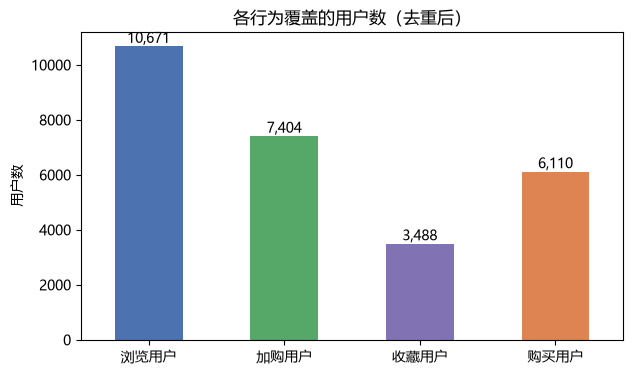

In [4]:
# 用户级（去重后）
uf = q(f"""
SELECT
  COUNT(DISTINCT CASE WHEN `行为类型`='pv'   THEN `用户ID` END) AS 浏览用户,
  COUNT(DISTINCT CASE WHEN `行为类型`='cart' THEN `用户ID` END) AS 加购用户,
  COUNT(DISTINCT CASE WHEN `行为类型`='fav'  THEN `用户ID` END) AS 收藏用户,
  COUNT(DISTINCT CASE WHEN `行为类型`='buy'  THEN `用户ID` END) AS 购买用户
FROM `{TABLE}` WHERE {DEDUP}
""").iloc[0]

strict = q(f"""
SELECT COUNT(*) AS 既浏览又购买用户 FROM (
  SELECT `用户ID` FROM `{TABLE}` WHERE {DEDUP} AND `行为类型` IN ('pv','buy')
  GROUP BY `用户ID`
  HAVING SUM(`行为类型`='pv') > 0 AND SUM(`行为类型`='buy') > 0
) t
""").iloc[0, 0]

print("用户级覆盖（去重后）：")
print(uf.to_string())
print()
print("覆盖率口径 浏览→购买：%.1f%%" % (uf['购买用户']/uf['浏览用户']*100))
print("严格口径   浏览→购买：%.1f%%  ← 主口径" % (strict/uf['浏览用户']*100))
print("（两口径相差 %d 个「没浏览直接买」的用户）" % (uf['购买用户'] - strict))
print("加购→购买：%.1f%%　购物车放弃率：%.1f%%"
      % (uf['购买用户']/uf['加购用户']*100, (1 - uf['购买用户']/uf['加购用户'])*100))

ax = uf.plot.bar(color=['#4C72B0','#55A868','#8172B3','#DD8452'], figsize=(7,4), rot=0)
ax.set_title('各行为覆盖的用户数（去重后）')
ax.set_ylabel('用户数')
for i, v in enumerate(uf):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom')
plt.show()

In [5]:
cat = q(f"""
SELECT `基础品类`,
       COUNT(DISTINCT CASE WHEN `行为类型`='pv'   THEN `用户ID` END) AS 浏览用户,
       COUNT(DISTINCT CASE WHEN `行为类型`='cart' THEN `用户ID` END) AS 加购用户,
       COUNT(DISTINCT CASE WHEN `行为类型`='buy'  THEN `用户ID` END) AS 购买用户
FROM `{TABLE}` WHERE {DEDUP}
GROUP BY `基础品类`
""")

cat['浏览→购买%'] = (cat['购买用户'] / cat['浏览用户'].replace(0, np.nan) * 100).round(2)
cat['加购→购买%'] = (cat['购买用户'] / cat['加购用户'].replace(0, np.nan) * 100).round(2)
cat = cat.replace([np.inf, -np.inf], np.nan)

print("=== 高流量低转化（浏览用户>=3000，按浏览→购买率升序）===")
display(cat.query('浏览用户 >= 3000').sort_values('浏览→购买%').head(10)
        [['基础品类','浏览用户','购买用户','浏览→购买%','加购→购买%']])

print("=== 高转化低流量（浏览用户 300~3000，按浏览→购买率降序）===")
display(cat.query('300 <= 浏览用户 < 3000').sort_values('浏览→购买%', ascending=False).head(10)
        [['基础品类','浏览用户','购买用户','浏览→购买%','加购→购买%']])

print("=== 购物车放弃率最高（加购用户>=200，按加购→购买率升序）===")
display(cat.query('加购用户 >= 200').sort_values('加购→购买%').head(10)
        [['基础品类','加购用户','购买用户','加购→购买%']])


=== 高流量低转化（浏览用户>=3000，按浏览→购买率升序）===


,基础品类,浏览用户,购买用户,浏览→购买%,加购→购买%
240,耳机,3349,78,2.33,14.36
3,LED台灯,3043,75,2.46,15.56
273,迷你蓝牙音箱,3090,80,2.59,16.88
14,中性笔,3390,119,3.51,23.15
10,USB风扇,3733,166,4.45,22.02
95,手机壳,4467,240,5.37,26.67
116,数据线,3696,216,5.84,26.09


=== 高转化低流量（浏览用户 300~3000，按浏览→购买率降序）===


,基础品类,浏览用户,购买用户,浏览→购买%,加购→购买%
4,Lightning转接头,321,65,20.25,141.30
156,桌游卡牌,644,123,19.10,121.78
25,修正带,427,72,16.86,101.41
231,美容面膜刷,305,50,16.39,111.11
184,瑜伽眼罩,374,60,16.04,85.71
214,移动电源,525,82,15.62,83.67
78,干燥剂,804,125,15.55,82.78
52,回形针,840,127,15.12,81.41
111,指甲油,1420,207,14.58,66.56
250,茶包,1627,236,14.51,67.24


=== 购物车放弃率最高（加购用户>=200，按加购→购买率升序）===


,基础品类,加购用户,购买用户,加购→购买%
240,耳机,543,78,14.36
3,LED台灯,482,75,15.56
122,方便面,206,33,16.02
273,迷你蓝牙音箱,474,80,16.88
162,梳子,249,48,19.28
10,USB风扇,754,166,22.02
14,中性笔,514,119,23.15
44,厨房开瓶器,371,95,25.61
116,数据线,828,216,26.09
289,面膜,301,80,26.58


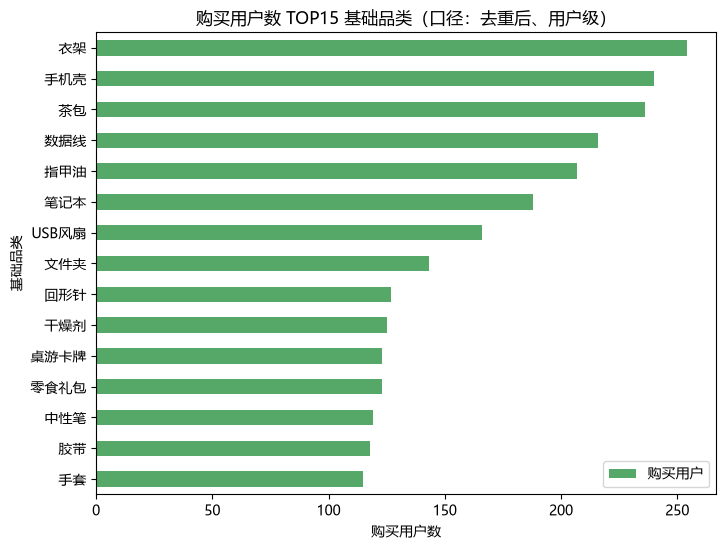

In [6]:
# 购买用户数 TOP15
top15 = cat.nlargest(15, '购买用户').sort_values('购买用户')
ax = top15.plot.barh(x='基础品类', y='购买用户', color='#55A868', figsize=(8,6))
ax.set_title('购买用户数 TOP15 基础品类（口径：去重后、用户级）')
ax.set_xlabel('购买用户数')
plt.show()

In [7]:
users = q(f"""
SELECT `用户ID`,
       SUM(CASE WHEN `行为类型`='buy'  THEN 1 ELSE 0 END) AS 购买次数,
       SUM(CASE WHEN `行为类型`='pv'   THEN 1 ELSE 0 END) AS 浏览次数,
       SUM(CASE WHEN `行为类型`='cart' THEN 1 ELSE 0 END) AS 加购次数,
       COUNT(DISTINCT `基础品类`) AS 品类数,
       COUNT(DISTINCT `日期`)     AS 活跃天数
FROM `{TABLE}` WHERE {DEDUP}
GROUP BY `用户ID`
""")
users['购买频次档'] = pd.cut(users['购买次数'], bins=[-1, 0, 1, 2, float('inf')],
                            labels=['0次', '1次', '2次', '3+次'])

tier = users.groupby('购买频次档', observed=True).agg(
    用户数=('用户ID', 'count'),
    人均浏览=('浏览次数', 'median'),
    人均加购=('加购次数', 'median'),
    人均品类=('品类数', 'median'),
    人均活跃天数=('活跃天数', 'median'),
)
tier


,用户数,人均浏览,人均加购,人均品类,人均活跃天数
购买频次档,,,,,
0次,4629,35.0,1.0,13.0,5.0
1次,2691,43.0,2.0,15.0,5.0
2次,1533,51.0,3.0,17.0,6.0
3+次,1886,66.0,4.0,21.0,6.0


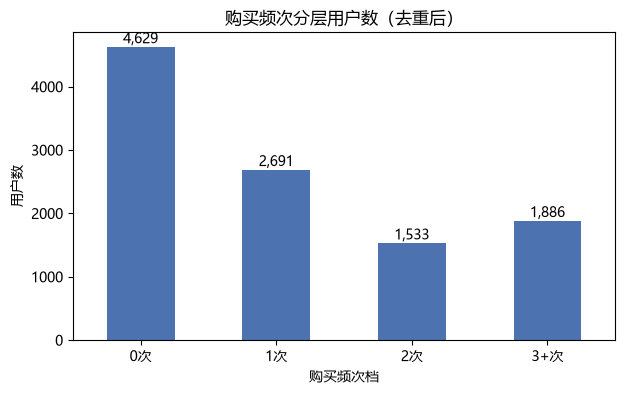

In [8]:
ax = tier['用户数'].plot.bar(color='#4C72B0', figsize=(7,4), rot=0)
ax.set_title('购买频次分层用户数（去重后）')
ax.set_ylabel('用户数')
for i, v in enumerate(tier['用户数']):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom')
plt.show()

In [9]:
faces = q(f"""
SELECT `人群标签`, COUNT(DISTINCT `用户ID`) AS 用户数
FROM `{TABLE}` GROUP BY `人群标签` HAVING 用户数 >= 50 ORDER BY 用户数 DESC
""")
top_faces = faces['人群标签'].tolist()
print("人数>=50 的人群：", len(top_faces), "个；", top_faces[:7])


人数>=50 的人群： 9 个； ['大学生', '上班族', '自由职业者', '游戏宅', '农民 / 种植户', '创业者', '互联网从业者']


In [10]:
def pref_index(beh):
    fc = q(f"""
    SELECT `人群标签` AS tag, `基础品类` AS cat, COUNT(DISTINCT `用户ID`) AS n_user
    FROM `{TABLE}` WHERE {DEDUP} AND `行为类型` = '{beh}' GROUP BY tag, cat
    """)
    SHRINK = 20
    cat_total = fc.groupby('cat')['n_user'].sum()
    face_total = fc.groupby('tag')['n_user'].sum()
    p_cat = cat_total / cat_total.sum()
    fc['偏好指数'] = ((fc['n_user'] + SHRINK * fc['cat'].map(p_cat))
                     / (fc['tag'].map(face_total) + SHRINK)
                     / fc['cat'].map(p_cat)).round(2)
    return fc

pref_buy = pref_index('buy')   # 购买偏好（选品/备货）
pref_pv  = pref_index('pv')    # 浏览偏好（拉新/兴趣）


In [11]:
print("=== 购买偏好 TOP（主群体，单元格样本>=30）===")
display(pref_buy[(pref_buy['tag'].isin(top_faces[:7])) & (pref_buy['n_user'] >= 30)]
        .sort_values('偏好指数', ascending=False)
        .groupby('tag', group_keys=False).head(5)[['tag','cat','n_user','偏好指数']])

print("=== 浏览偏好 TOP（主群体，单元格样本>=30）===")
display(pref_pv[(pref_pv['tag'].isin(top_faces[:7])) & (pref_pv['n_user'] >= 30)]
        .sort_values('偏好指数', ascending=False)
        .groupby('tag', group_keys=False).head(5)[['tag','cat','n_user','偏好指数']])


=== 购买偏好 TOP（主群体，单元格样本>=30）===


,tag,cat,n_user,偏好指数
3392,自由职业者,USB风扇,37,1.66
2754,游戏宅,文件夹,31,1.58
1701,大学生,手机壳,45,1.35
1098,农民 / 种植户,茶包,33,1.25
3476,自由职业者,手机壳,38,1.18
2746,游戏宅,指甲油,31,1.09
1102,农民 / 种植户,衣架,31,1.09
1716,大学生,指甲油,30,1.05
1849,大学生,衣架,37,1.05
2730,游戏宅,手机壳,34,1.04


=== 浏览偏好 TOP（主群体，单元格样本>=30）===


,tag,cat,n_user,偏好指数
4158,创业者,便携式WiFi热点,35,1.77
6200,大学生,智能睡眠眼罩,41,1.55
1240,互联网从业者,仿真花,47,1.50
3814,农民 / 种植户,瑜伽袜,51,1.49
1425,互联网从业者,白板笔,32,1.45
3863,农民 / 种植户,美甲灯,72,1.44
1497,互联网从业者,迷你麦克风,30,1.43
3861,农民 / 种植户,美甲亮片,60,1.43
15778,自由职业者,多功能读卡器,66,1.41
11977,游戏宅,汽车空气净化器,41,1.41


In [12]:
gender = q(f"""
SELECT `性别`, COUNT(DISTINCT `用户ID`) AS 用户数,
       COUNT(DISTINCT CASE WHEN `行为类型`='buy' THEN `用户ID` END) AS 购买用户
FROM `{TABLE}` WHERE {DEDUP} GROUP BY `性别`
""")
gender

gender_cat = q(f"""
SELECT `性别`, `基础品类`, COUNT(DISTINCT CASE WHEN `行为类型`='buy' THEN `用户ID` END) AS 购买用户
FROM `{TABLE}` WHERE {DEDUP} GROUP BY `性别`, `基础品类`
""")

g = gender_cat.copy()
sex_total = g.groupby('性别')['购买用户'].transform('sum')
cat_total = g.groupby('基础品类')['购买用户'].transform('sum')
all_total = g['购买用户'].sum()
g['lift'] = ((g['购买用户'] / sex_total) / (cat_total / all_total)).round(2)

for s in ['男', '女']:
    print(f"=== {s} 规模榜 TOP8（按购买用户数）===")
    display(gender_cat.query("性别 == @s").nlargest(8, '购买用户'))
    print(f"=== {s} 偏好榜 TOP8（按 lift，购买用户>=30）===")
    display(g.query("性别 == @s and 购买用户 >= 30").nlargest(8, 'lift')[['基础品类','购买用户','lift']])


=== 男 规模榜 TOP8（按购买用户数）===


,性别,基础品类,购买用户
556,男,衣架,119
396,男,手机壳,105
551,男,茶包,100
412,男,指甲油,93
417,男,数据线,89
311,男,USB风扇,81
519,男,笔记本,75
420,男,文件夹,63


=== 男 偏好榜 TOP8（按 lift，购买用户>=30）===


,基础品类,购买用户,lift
517,空气清新剂,43,1.41
354,围巾,35,1.28
460,桌面收纳架,30,1.21
470,洗衣袋,38,1.18
544,耳钉,37,1.17
594,鞋垫,33,1.15
311,USB风扇,81,1.14
339,化妆刷,55,1.13


=== 女 规模榜 TOP8（按购买用户数）===


,性别,基础品类,购买用户
250,女,茶包,136
95,女,手机壳,135
255,女,衣架,135
116,女,数据线,127
111,女,指甲油,114
218,女,笔记本,113
10,女,USB风扇,85
119,女,文件夹,80


=== 女 偏好榜 TOP8（按 lift，购买用户>=30）===


,基础品类,购买用户,lift
23,保温杯,39,1.31
203,相册,32,1.22
65,宠物喂食器,31,1.21
284,降噪耳塞,31,1.21
106,折叠水壶,43,1.19
114,收纳盒,44,1.18
72,小型玩偶,30,1.17
179,火柴盒,49,1.17


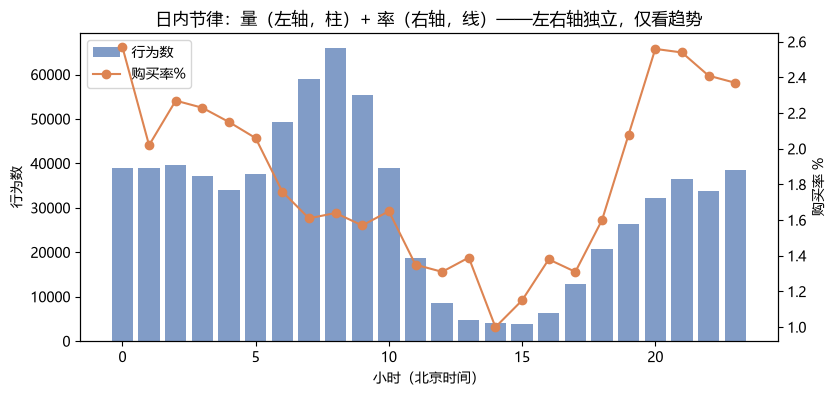

In [13]:
hour = q(f"""
SELECT `小时`, COUNT(*) AS 行为数,
       SUM(CASE WHEN `行为类型`='buy' THEN 1 ELSE 0 END) AS 购买数
FROM `{TABLE}` WHERE {DEDUP} GROUP BY `小时` ORDER BY `小时`
""")
hour['购买率%'] = (hour['购买数'] / hour['行为数'] * 100).round(2)

fig, ax1 = plt.subplots(figsize=(9,4))
ax1.bar(hour['小时'], hour['行为数'], color='#4C72B0', alpha=0.7, label='行为数')
ax1.set_xlabel('小时（北京时间）'); ax1.set_ylabel('行为数')
ax2 = ax1.twinx()
ax2.plot(hour['小时'], hour['购买率%'], color='#DD8452', marker='o', label='购买率%')
ax2.set_ylabel('购买率 %')
ax1.set_title('日内节律：量（左轴，柱）+ 率（右轴，线）——左右轴独立，仅看趋势')
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, loc='upper left')
plt.show()

In [14]:
week = q(f"""
SELECT `星期`, COUNT(*) AS 行为数,
       SUM(CASE WHEN `行为类型`='buy' THEN 1 ELSE 0 END) AS 购买数
FROM `{TABLE}` WHERE {DEDUP} AND {FULL_DAYS}
GROUP BY `星期`
""").set_index('星期').reindex(['周四','周五','周六','周日','周一'])
week['购买率%'] = (week['购买数'] / week['行为数'] * 100).round(2)
week[['行为数','购买数','购买率%']]

,行为数,购买数,购买率%
星期,,,
周四,106367,2247.0,2.11
周五,110154,2395.0,2.17
周六,112416,2233.0,1.99
周日,128970,2415.0,1.87
周一,153002,2835.0,1.85


In [15]:
rep = q(f"""
SELECT
  COUNT(DISTINCT CASE WHEN 购买次数 > 1 THEN `用户ID` END) AS 复购用户数,
  COUNT(DISTINCT `用户ID`)                                   AS 购买用户数,
  SUM(CASE WHEN 购买次数 > 1 THEN 1 ELSE 0 END)              AS 复购组合数,
  COUNT(*)                                                   AS 购买组合数
FROM (
  SELECT `用户ID`, `商品ID`, COUNT(*) AS 购买次数
  FROM `{TABLE}` WHERE {DEDUP} AND `行为类型`='buy'
  GROUP BY `用户ID`, `商品ID`
) t
""").iloc[0]

print("窗口内用户级复购率：%.1f%%" % (rep['复购用户数'] / rep['购买用户数'] * 100))
print("窗口内组合级复购率：%.1f%%" % (rep['复购组合数'] / rep['购买组合数'] * 100))


窗口内用户级复购率：6.8%
窗口内组合级复购率：3.7%
